# Eksperimen Komparasi Metrik Jarak pada Algoritma Clustering
**Dataset PBL: Lettuce (hidroponik)** + dataset kontrol (`make_blobs`, `make_moons`)
9 konfigurasi = 3 algoritma (K-Means, DBSCAN, Hierarchical) × 3 metrik (Euclidean, Manhattan, Cosine).

Aturan yang diikuti (dari outline UTS): Euclidean/Manhattan memakai `StandardScaler`, Cosine memakai `Normalizer(l2)`; K-Means–Manhattan = K-Medians, K-Means–Cosine = spherical k-means; Hierarchical memakai **average linkage** untuk ketiga metrik; k sama untuk K-Means & Hierarchical; eps DBSCAN dari k-distance plot terpisah per metrik (k = min_samples); noise **dikeluarkan** saat menghitung Silhouette/DBI; `random_state=42`.

## 1. Setup, Reproducibility & Konfigurasi

In [ ]:
import os, sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, scipy
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import cdist, pdist
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

RS = 42; np.random.seed(RS)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")

DATA_PATHS = ['lettuce_dataset_updated.csv', '/content/lettuce_dataset_updated.csv',
              '/mnt/user-data/uploads/lettuce_dataset_updated.csv']
FEATURES = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
N_CONTROL = 500
METRICS = ['Euclidean', 'Manhattan', 'Cosine']
SCIPY_METRIC = {'Euclidean': 'euclidean', 'Manhattan': 'cityblock', 'Cosine': 'cosine'}
SK_METRIC = {'Euclidean': 'euclidean', 'Manhattan': 'manhattan', 'Cosine': 'cosine'}
K_OVERRIDE = None # K nya di dapat dari hasil silhouete score tertinggi tapi jika mau ganti/timpa bisa disini
EPS_OVERRIDE = {} # ini untuk timpa eps jika hasil tidak mau hasil eps berdasarkan k distance

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | scipy 1.16.3


## 2. Dataset & Praproses
- **Missing value**: diisi median (robust terhadap outlier, tidak membuang baris).
- **Outlier**: dicek dengan IQR tetapi **tidak dihapus** (DBSCAN memang mendeteksi noise; K-Medians/Manhattan lebih tahan outlier).
- **Fitur**: 5 fitur numerik sensor; kolom redundan (`Temperature (F)`, `Humidity`) dan `Plant_ID`/`Date` tidak dipakai. Tidak ada fitur kategorikal/teks.
- **Ground truth**: `Plant_ID` adalah identitas tanaman, bukan label cluster, sehingga **tidak dipakai** sebagai label. ARI/NMI = "–" untuk dataset PBL.
- **Skala**: `StandardScaler` (Euclidean & Manhattan); `StandardScaler` → `Normalizer(l2)` (Cosine).

In [ ]:
path = next((p for p in DATA_PATHS if os.path.exists(p)), None)
assert path, 'File lettuce_dataset_updated.csv tidak ditemukan - upload dulu / sesuaikan DATA_PATHS'
df = pd.read_csv(path, encoding='latin1')
print('Ukuran:', df.shape, '| Missing total:', int(df[FEATURES].isna().sum().sum()), '| Duplikat:', int(df.duplicated().sum()))
df[FEATURES] = df[FEATURES].fillna(df[FEATURES].median())
for c in FEATURES:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    print(f"Outlier IQR {c:18s}: {int(((df[c] < q1-1.5*i) | (df[c] > q3+1.5*i)).sum())}")
display(df[FEATURES].describe().T)

def make_entry(X_raw, y, k_fixed):
    Xs = StandardScaler().fit_transform(X_raw)
    Xc = Normalizer(norm='l2').fit_transform(Xs)
    Xv = PCA(n_components=2, random_state=RS).fit_transform(Xs) if Xs.shape[1] > 2 else Xs  # hanya visualisasi
    return dict(data={'Euclidean': Xs, 'Manhattan': Xs, 'Cosine': Xc}, y=y, k=k_fixed, Xv=Xv, dim=Xs.shape[1])

Xb, yb = make_blobs(n_samples=N_CONTROL, centers=4, random_state=RS)
Xm, ym = make_moons(n_samples=N_CONTROL, noise=0.1, random_state=RS)
DATASETS = {'Lettuce (PBL)': make_entry(df[FEATURES].values, None, None),
            'Blobs (kontrol)': make_entry(Xb, yb, 4),
            'Moons (kontrol)': make_entry(Xm, ym, 2)}
for n, d in DATASETS.items(): print(f"{n:16s}: n={len(d['Xv'])}, dim={d['dim']}")

Ukuran: (3169, 9) | Missing total: 0 | Duplikat: 0
Outlier IQR Temperature (°C)  : 0
Outlier IQR Humidity (%)      : 0
Outlier IQR TDS Value (ppm)   : 0
Outlier IQR pH Level          : 0
Outlier IQR Growth Days       : 0


,count,mean,std,min,25%,50%,75%,max
Temperature (°C),3169.0,28.142222,4.670521,18.0,23.6,30.2,31.5,33.5
Humidity (%),3169.0,64.873462,8.988985,50.0,57.0,65.0,73.0,80.0
TDS Value (ppm),3169.0,598.045440,115.713047,400.0,498.0,593.0,699.0,800.0
pH Level,3169.0,6.399211,0.234418,6.0,6.2,6.4,6.6,6.8
Growth Days,3169.0,23.141054,13.077107,1.0,12.0,23.0,34.0,48.0


Lettuce (PBL)   : n=3169, dim=5
Blobs (kontrol) : n=500, dim=2
Moons (kontrol) : n=500, dim=2


## 3. Fungsi Algoritma & Evaluasi

In [ ]:
class KMedians:
    """K-Medians (L1): assignment pakai jarak Manhattan, centroid = median. n_init=10 seperti KMeans."""
    def __init__(self, n_clusters, max_iter=100, n_init=10, random_state=RS):
        self.k, self.max_iter, self.n_init, self.rs = n_clusters, max_iter, n_init, random_state
    def fit(self, X):
        rng = np.random.RandomState(self.rs); best = None
        for _ in range(self.n_init):
            cen = X[rng.choice(len(X), self.k, replace=False)]
            for _ in range(self.max_iter):
                lab = cdist(X, cen, 'cityblock').argmin(1)
                new = np.array([np.median(X[lab == j], 0) if (lab == j).any() else cen[j] for j in range(self.k)])
                if np.allclose(new, cen): break
                cen = new
            cost = cdist(X, cen, 'cityblock').min(1).sum()   # sum of absolute error
            if best is None or cost < best[0]: best = (cost, lab, cen)
        self.inertia_, self.labels_, self.centroids_ = best
        return self

def run_kmeans(X, k, metric):
    if metric == 'Manhattan':
        m = KMedians(k).fit(X)
    else:  # Euclidean: KMeans bawaan; Cosine: X sudah L2-normal -> spherical k-means
        m = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    return m.labels_, m.inertia_

def run_dbscan(X, eps, min_samples, metric):
    kw = dict(algorithm='brute') if metric == 'Cosine' else {}
    return DBSCAN(eps=eps, min_samples=min_samples, metric=SK_METRIC[metric], **kw).fit_predict(X)

def run_hier(X, k, metric):
    return AgglomerativeClustering(n_clusters=k, metric=SK_METRIC[metric], linkage='average').fit_predict(X)

def kdistance(X, min_samples, metric):
    # k = min_samples (titik itu sendiri dihitung sbg tetangga pertama, sama seperti DBSCAN)
    nn = NearestNeighbors(n_neighbors=min_samples, metric=SK_METRIC[metric],
                          algorithm='brute' if metric == 'Cosine' else 'auto').fit(X)
    return np.sort(nn.kneighbors(X)[0][:, -1])

def knee_eps(d):
    # titik dengan jarak terjauh dari garis lurus ujung-ke-ujung kurva (heuristik knee)
    x = np.linspace(0, 1, len(d)); y = (d - d.min()) / (d.max() - d.min() + 1e-12)
    return float(d[np.argmax(x - y)])

def evaluate(X, lab, metric, y=None):
    mask = lab != -1                      # noise DIKELUARKAN dari Silhouette & DBI
    ncl = len(set(lab[mask])); sil = dbi = np.nan
    if ncl >= 2 and mask.sum() > ncl:
        sil = silhouette_score(X[mask], lab[mask], metric=SK_METRIC[metric])   # metrik sama dg clustering
        dbi = davies_bouldin_score(X[mask], lab[mask])                          # selalu Euclidean
    ari = nmi = np.nan
    if y is not None: ari, nmi = adjusted_rand_score(y, lab), normalized_mutual_info_score(y, lab)
    return dict(k=ncl, noise=100 * (~mask).mean(), sil=sil, dbi=dbi, ari=ari, nmi=nmi)

def timed(fn, n=3):
    ts = []
    for _ in range(n):
        t = time.perf_counter(); out = fn(); ts.append((time.perf_counter() - t) * 1000)
    return out, float(np.mean(ts))

## 4. Penentuan k (Elbow + Silhouette)
Dataset kontrol: k dikunci (Blobs = 4, Moons = 2). Dataset PBL: k dipilih dari Silhouette tertinggi pada K-Means Euclidean, lalu **k yang sama** dipakai untuk K-Medians, spherical k-means, dan Hierarchical.

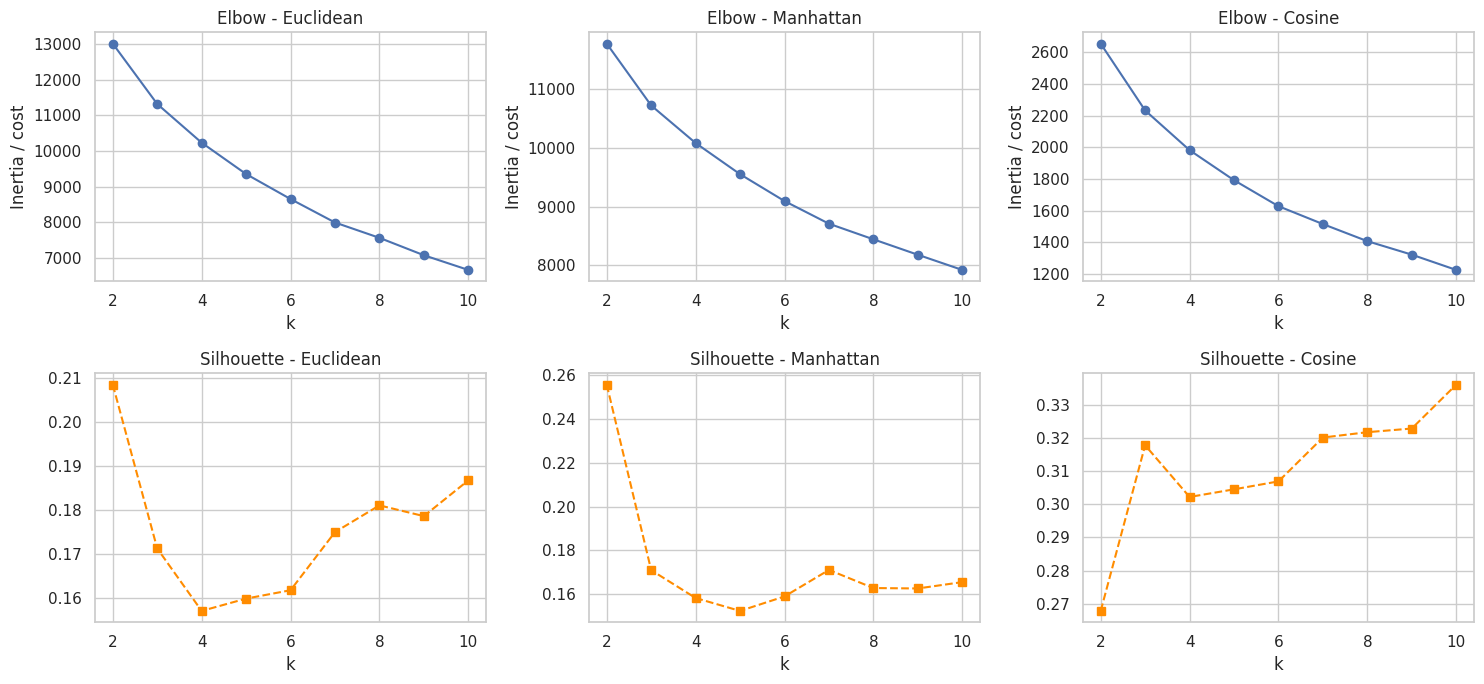

Lettuce (PBL)    k = 2
Blobs (kontrol)  k = 4
Moons (kontrol)  k = 2


In [ ]:
K_RANGE = range(2, 11)
d = DATASETS['Lettuce (PBL)']
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
sil_euc = None
for j, m in enumerate(METRICS):
    X = d['data'][m]; sse, sil = [], []
    for k in K_RANGE:
        lab, cost = run_kmeans(X, k, m); sse.append(cost); sil.append(silhouette_score(X, lab, metric=SK_METRIC[m]))
    if m == 'Euclidean': sil_euc = sil
    ax[0, j].plot(K_RANGE, sse, 'o-'); ax[0, j].set_title(f'Elbow - {m}'); ax[0, j].set_xlabel('k'); ax[0, j].set_ylabel('Inertia / cost')
    ax[1, j].plot(K_RANGE, sil, 's--', c='darkorange'); ax[1, j].set_title(f'Silhouette - {m}'); ax[1, j].set_xlabel('k')
plt.tight_layout(); plt.show()
d['k'] = K_OVERRIDE or list(K_RANGE)[int(np.argmax(sil_euc))]
for n in DATASETS: print(f"{n:16s} k = {DATASETS[n]['k']}")

## 5. Menjalankan 9 Konfigurasi + Tabel Ringkasan

In [ ]:
RES, LABELS, EPS, MINS, COPH = {}, {}, {}, {}, {}
for dn, d in DATASETS.items():
    k = d['k']; ms = max(4, 2 * d['dim']); MINS[dn] = ms; rows = []
    for m in METRICS:
        X = d['data'][m]
        # K-Means / K-Medians / spherical
        (lab, _), t = timed(lambda: run_kmeans(X, k, m)); LABELS[dn, 'K-Means*', m] = lab
        rows.append(dict(Algoritma='K-Means*', Metrik=m, **evaluate(X, lab, m, d['y']), ms=t))
        # DBSCAN (eps dari k-distance per metrik)
        kd = kdistance(X, ms, m); eps = EPS_OVERRIDE.get((dn, m), knee_eps(kd)); EPS[dn, m] = (eps, kd)
        lab, t = timed(lambda: run_dbscan(X, eps, ms, m)); LABELS[dn, 'DBSCAN', m] = lab
        rows.append(dict(Algoritma='DBSCAN', Metrik=m, **evaluate(X, lab, m, d['y']), ms=t))
        # Hierarchical average linkage
        lab, t = timed(lambda: run_hier(X, k, m)); LABELS[dn, 'Hierarchical', m] = lab
        rows.append(dict(Algoritma='Hierarchical', Metrik=m, **evaluate(X, lab, m, d['y']), ms=t))
        Z = linkage(X, 'average', metric=SCIPY_METRIC[m]); COPH[dn, m] = (Z, cophenet(Z, pdist(X, SCIPY_METRIC[m]))[0])
    t = pd.DataFrame(rows).rename(columns={'noise': '% noise', 'sil': 'Silhouette', 'dbi': 'DBI', 'ari': 'ARI', 'nmi': 'NMI', 'ms': 'Waktu (ms)'})
    RES[dn] = t[['Algoritma', 'Metrik', 'k', '% noise', 'Silhouette', 'DBI', 'ARI', 'NMI', 'Waktu (ms)']]

for dn, t in RES.items():
    print(f"\n=== {dn} === (noise dikeluarkan saat hitung Silhouette/DBI; k DBSCAN = jumlah cluster hasil temuan)")
    display(t.style.format({'% noise': '{:.1f}', 'Silhouette': '{:.4f}', 'DBI': '{:.4f}', 'ARI': '{:.4f}', 'NMI': '{:.4f}',
                            'Waktu (ms)': '{:.1f}'}, na_rep='–').hide(axis='index'))
print('\nCophenetic correlation (Hierarchical, average linkage):')
display(pd.DataFrame({dn: {m: COPH[dn, m][1] for m in METRICS} for dn in DATASETS}).round(4))


=== Lettuce (PBL) === (noise dikeluarkan saat hitung Silhouette/DBI; k DBSCAN = jumlah cluster hasil temuan)


Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
K-Means*,Euclidean,2,0.0,0.2085,1.9233,–,–,33.2
DBSCAN,Euclidean,2,0.9,0.2085,1.9138,–,–,68.6
Hierarchical,Euclidean,2,0.0,0.2085,1.9233,–,–,266.7
K-Means*,Manhattan,2,0.0,0.2558,1.9233,–,–,59.7
DBSCAN,Manhattan,2,0.9,0.1004,0.9931,–,–,99.1
Hierarchical,Manhattan,2,0.0,0.2554,1.9224,–,–,269.8
K-Means*,Cosine,2,0.0,0.2679,2.2656,–,–,29.7
DBSCAN,Cosine,2,0.3,0.2926,1.9607,–,–,118.0
Hierarchical,Cosine,2,0.0,0.2931,1.9598,–,–,287.2



=== Blobs (kontrol) === (noise dikeluarkan saat hitung Silhouette/DBI; k DBSCAN = jumlah cluster hasil temuan)


Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
K-Means*,Euclidean,4,0.0,0.7979,0.2819,1.0000,1.0000,13.1
DBSCAN,Euclidean,7,9.0,0.6414,0.4520,0.8412,0.8312,4.6
Hierarchical,Euclidean,4,0.0,0.7979,0.2819,1.0000,1.0000,9.7
K-Means*,Manhattan,4,0.0,0.7900,0.2819,1.0000,1.0000,20.0
DBSCAN,Manhattan,7,8.2,0.6251,0.4567,0.8532,0.8397,4.6
Hierarchical,Manhattan,4,0.0,0.7900,0.2819,1.0000,1.0000,5.8
K-Means*,Cosine,4,0.0,0.9699,0.1891,1.0000,1.0000,12.2
DBSCAN,Cosine,4,3.8,0.9774,0.1715,0.9470,0.9267,7.3
Hierarchical,Cosine,4,0.0,0.9699,0.1891,1.0000,1.0000,10.3



=== Moons (kontrol) === (noise dikeluarkan saat hitung Silhouette/DBI; k DBSCAN = jumlah cluster hasil temuan)


Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
K-Means*,Euclidean,2,0.0,0.4900,0.8165,0.4451,0.3515,11.9
DBSCAN,Euclidean,2,3.6,0.3859,1.0109,0.9293,0.8825,4.7
Hierarchical,Euclidean,2,0.0,0.4563,0.8567,0.6329,0.6141,10.4
K-Means*,Manhattan,2,0.0,0.4839,0.8262,0.4292,0.3378,22.3
DBSCAN,Manhattan,2,2.4,0.3779,1.0094,0.9525,0.9129,5.1
Hierarchical,Manhattan,2,0.0,0.4484,0.8666,0.6916,0.6597,5.4
K-Means*,Cosine,2,0.0,0.7142,0.7757,0.4451,0.3515,10.4
DBSCAN,Cosine,13,3.0,0.3418,0.4443,0.1700,0.2613,6.5
Hierarchical,Cosine,2,0.0,0.7105,0.7801,0.4239,0.3332,12.2



Cophenetic correlation (Hierarchical, average linkage):


,Lettuce (PBL),Blobs (kontrol),Moons (kontrol)
Euclidean,0.5309,0.9430,0.7449
Manhattan,0.5395,0.9343,0.7258
Cosine,0.5259,0.8885,0.8360


## 6. Visualisasi Grid 3×3 (baris = algoritma, kolom = metrik)
Proyeksi PCA 2D hanya untuk visualisasi; clustering dijalankan pada data asli. Noise DBSCAN = tanda ×.

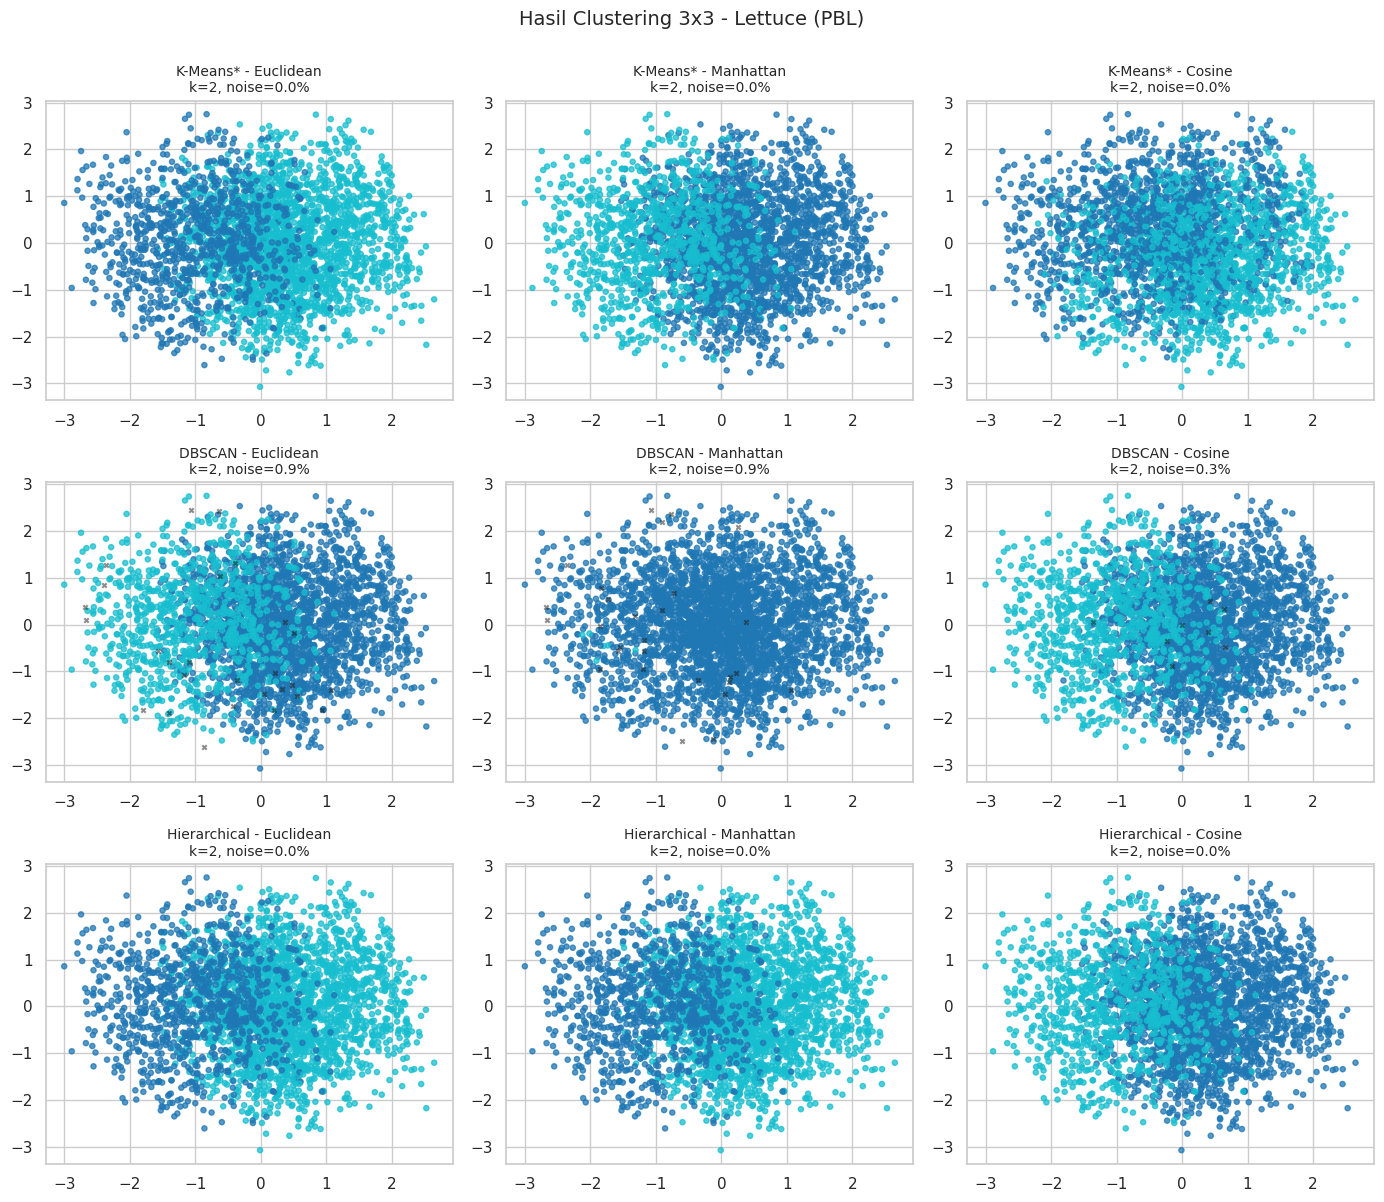

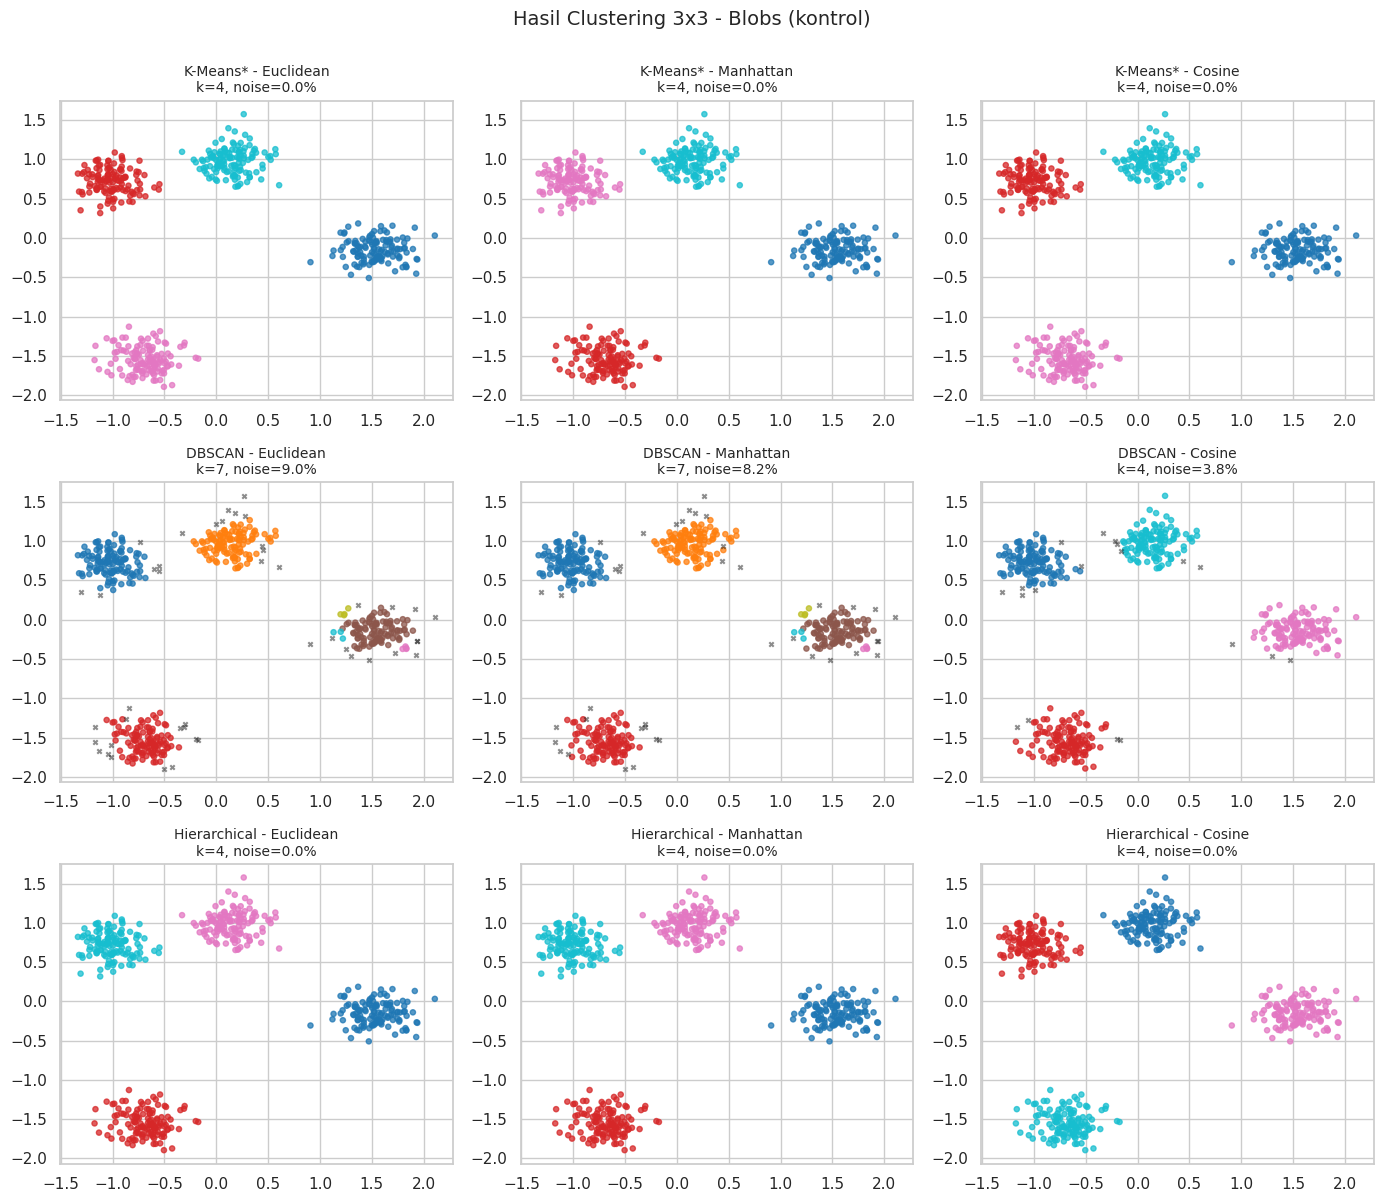

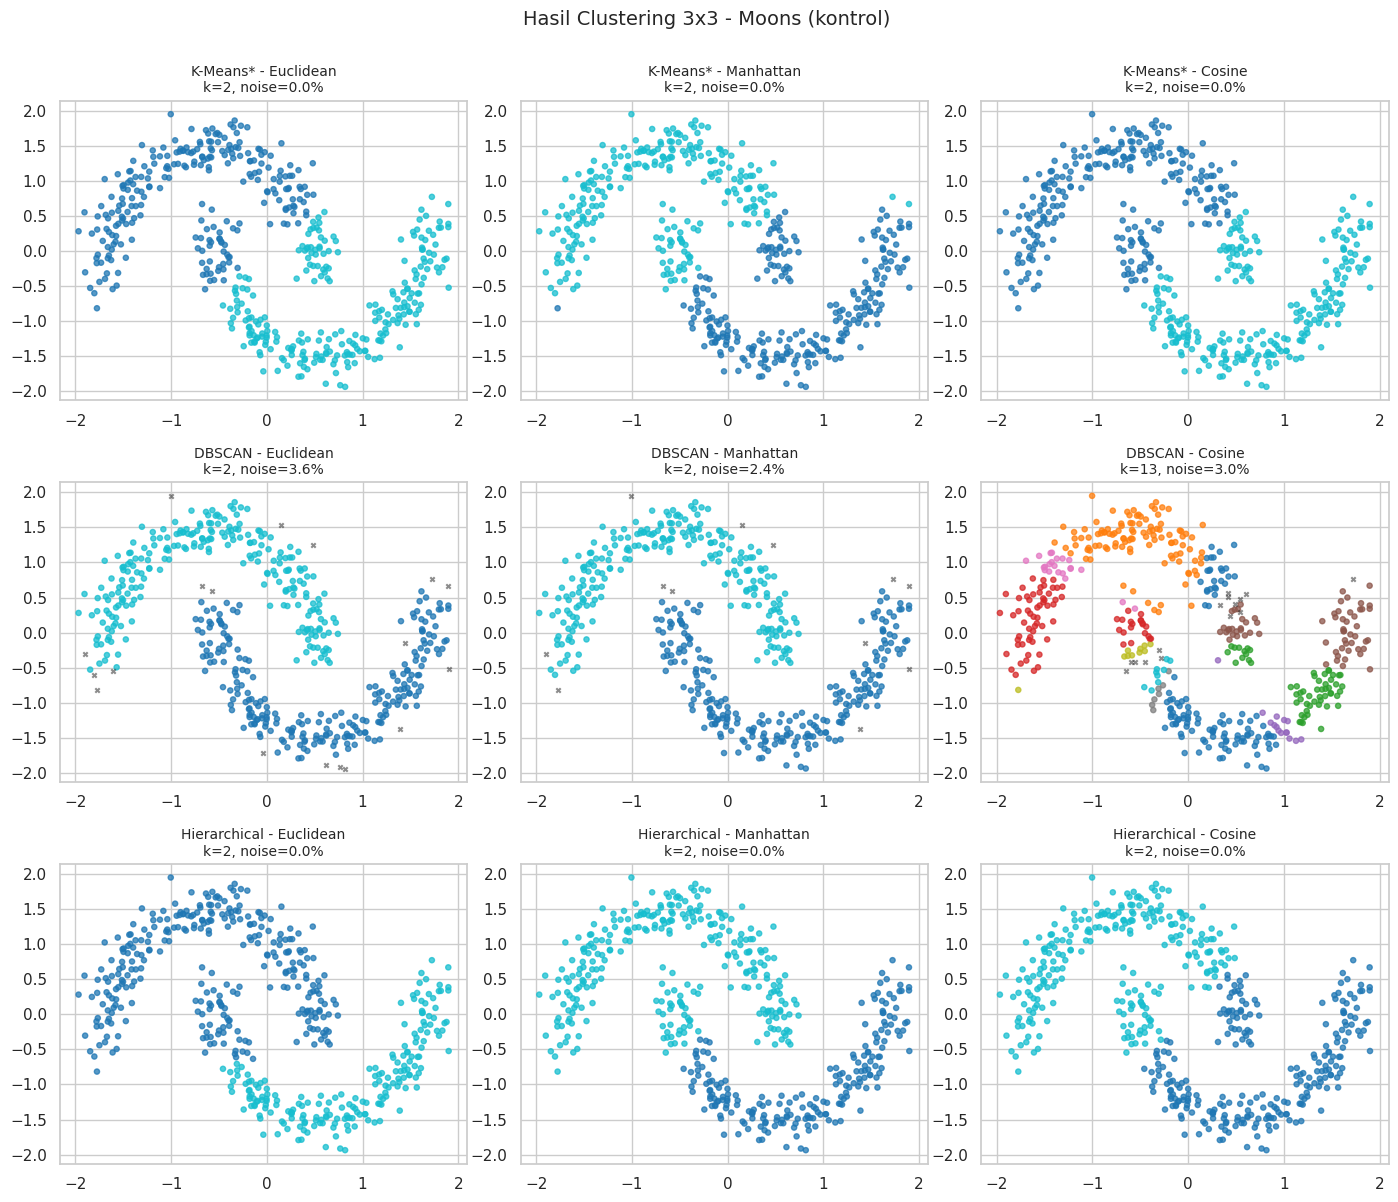

In [ ]:
ALGS = ['K-Means*', 'DBSCAN', 'Hierarchical']
for dn, d in DATASETS.items():
    fig, ax = plt.subplots(3, 3, figsize=(14, 12)); Xv = d['Xv']
    for i, a in enumerate(ALGS):
        for j, m in enumerate(METRICS):
            lab = LABELS[dn, a, m]; nz = lab == -1
            ax[i, j].scatter(Xv[~nz, 0], Xv[~nz, 1], c=lab[~nz], cmap='tab10', s=14, alpha=.75)
            if nz.any(): ax[i, j].scatter(Xv[nz, 0], Xv[nz, 1], c='k', marker='x', s=10, alpha=.5)
            r = RES[dn].query('Algoritma==@a and Metrik==@m').iloc[0]
            ax[i, j].set_title(f"{a} - {m}\nk={int(r.k)}, noise={r['% noise']:.1f}%", fontsize=10)
    plt.suptitle(f'Hasil Clustering 3x3 - {dn}', fontsize=14, y=1.00); plt.tight_layout(); plt.show()

## 7. Grafik Penyetelan: k-distance DBSCAN & Dendrogram (garis potong ditandai)

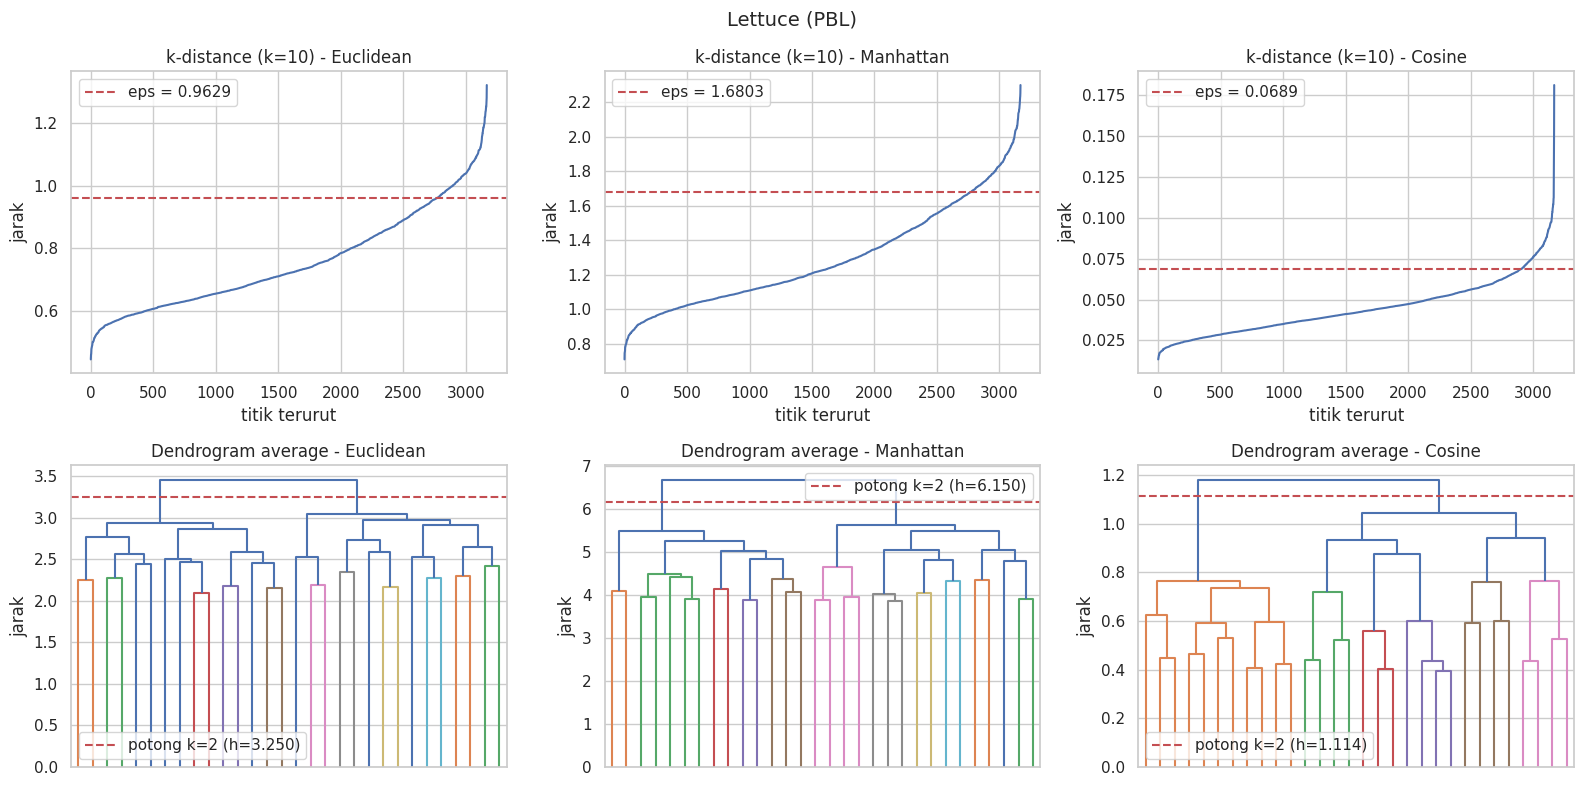

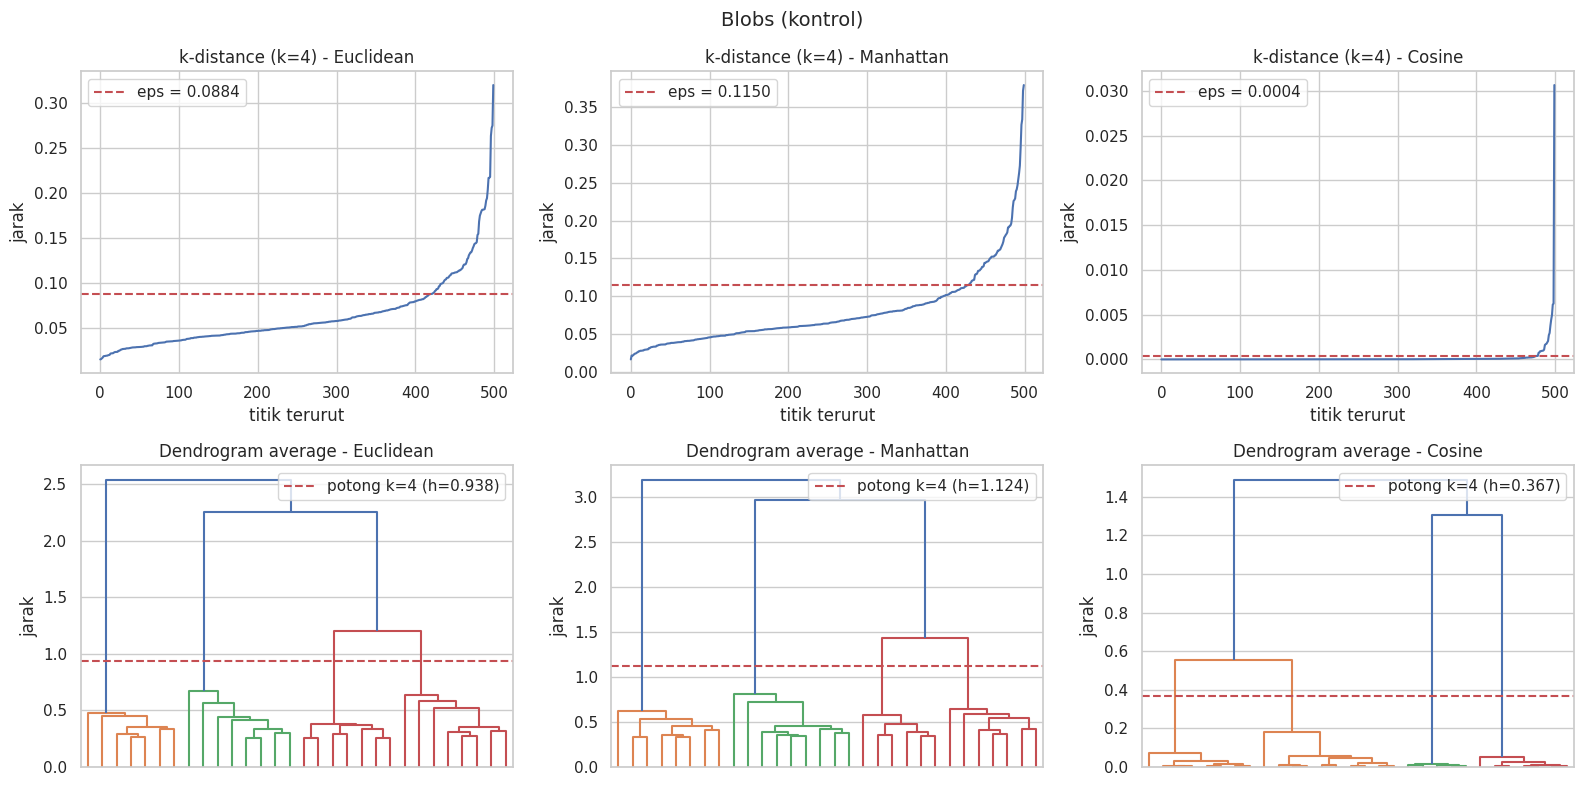

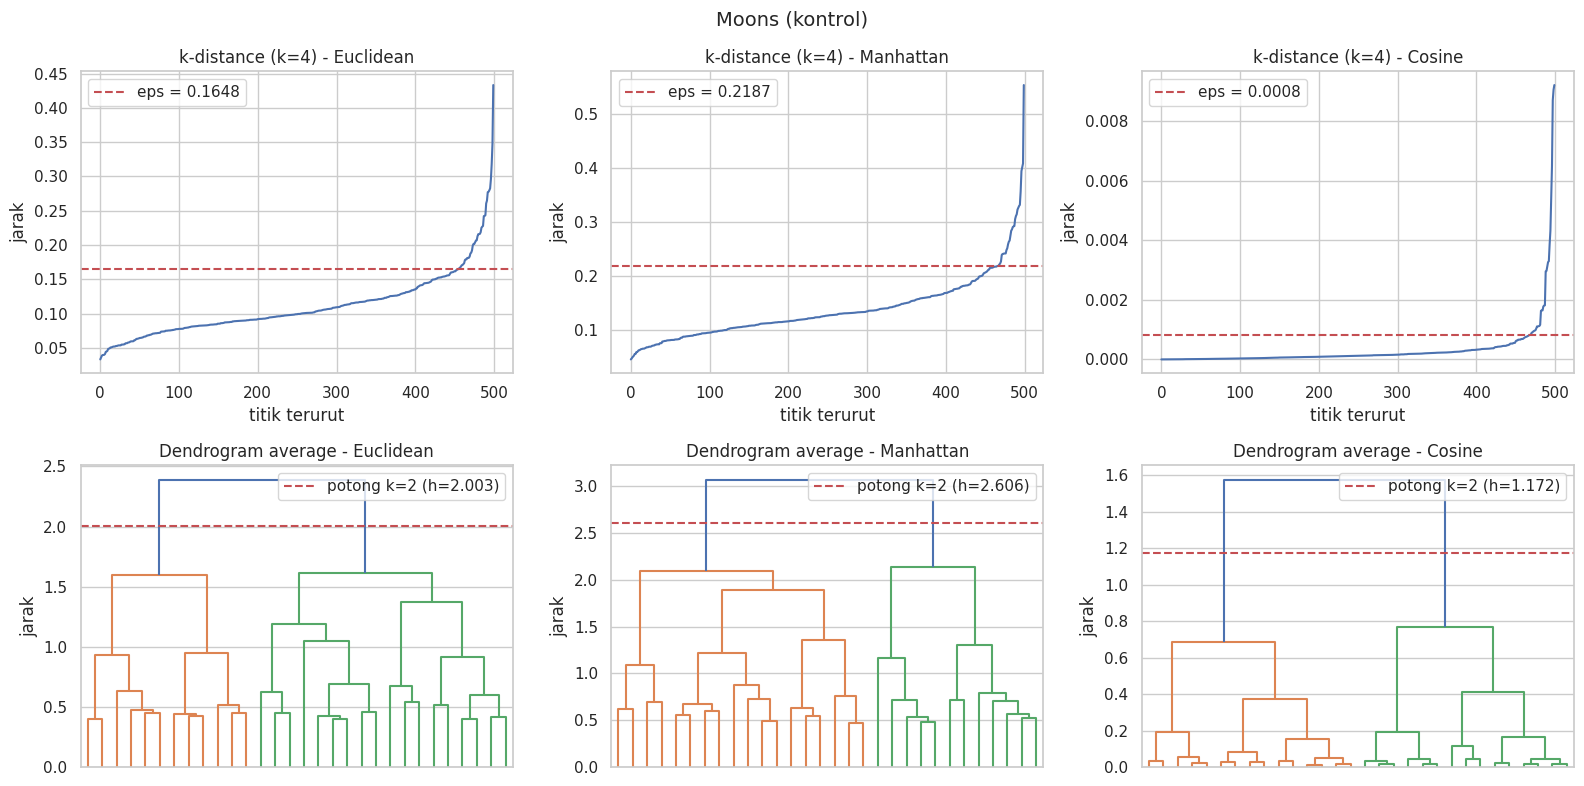

In [ ]:
for dn, d in DATASETS.items():
    fig, ax = plt.subplots(2, 3, figsize=(16, 8)); k = d['k']
    for j, m in enumerate(METRICS):
        eps, kd = EPS[dn, m]
        ax[0, j].plot(kd); ax[0, j].axhline(eps, c='r', ls='--', label=f'eps = {eps:.4f}')
        ax[0, j].set_title(f'k-distance (k={MINS[dn]}) - {m}'); ax[0, j].set_xlabel('titik terurut'); ax[0, j].set_ylabel('jarak'); ax[0, j].legend()
        Z = COPH[dn, m][0]; cut = (Z[-(k - 1), 2] + Z[-k, 2]) / 2
        dendrogram(Z, truncate_mode='lastp', p=30, no_labels=True, ax=ax[1, j])
        ax[1, j].axhline(cut, c='r', ls='--', label=f'potong k={k} (h={cut:.3f})'); ax[1, j].legend()
        ax[1, j].set_title(f'Dendrogram average - {m}'); ax[1, j].set_ylabel('jarak')
    plt.suptitle(dn, fontsize=14); plt.tight_layout(); plt.show()

## 8. Pembanding Tambahan: Ward (hanya Euclidean, di luar matriks 3×3)

In [ ]:
for dn, d in DATASETS.items():
    X = d['data']['Euclidean']; lab = AgglomerativeClustering(n_clusters=d['k'], linkage='ward').fit_predict(X)
    e = evaluate(X, lab, 'Euclidean', d['y'])
    print(f"{dn:16s} Ward k={d['k']} | Silhouette={e['sil']:.4f} | DBI={e['dbi']:.4f} | ARI={e['ari']:.4f} | NMI={e['nmi']:.4f}")

Lettuce (PBL)    Ward k=2 | Silhouette=0.2085 | DBI=1.9233 | ARI=nan | NMI=nan
Blobs (kontrol)  Ward k=4 | Silhouette=0.7979 | DBI=0.2819 | ARI=1.0000 | NMI=1.0000
Moons (kontrol)  Ward k=2 | Silhouette=0.4563 | DBI=0.8567 | ARI=0.6329 | NMI=0.6141


## 9. Tabel Parameter Final & Karakteristik Data (untuk Lampiran / Bab 2.4)

In [ ]:
rows = []
for dn, d in DATASETS.items():
    for m in METRICS:
        rows += [dict(Dataset=dn, Algoritma={'Euclidean': 'K-Means', 'Manhattan': 'K-Medians', 'Cosine': 'Spherical K-Means'}[m], Metrik=m,
                      Parameter=f"k={d['k']}, random_state={RS}"),
                 dict(Dataset=dn, Algoritma='DBSCAN', Metrik=m, Parameter=f"eps={EPS[dn, m][0]:.4f}, min_samples={MINS[dn]}"),
                 dict(Dataset=dn, Algoritma='Hierarchical', Metrik=m, Parameter=f"linkage=average, n_clusters={d['k']}")]
display(pd.DataFrame(rows).style.hide(axis='index'))
print('\nKarakteristik: ', {n: dict(n=len(d['Xv']), dim=d['dim'], label='Ya' if d['y'] is not None else 'Tidak') for n, d in DATASETS.items()})

Dataset,Algoritma,Metrik,Parameter
Lettuce (PBL),K-Means,Euclidean,"k=2, random_state=42"
Lettuce (PBL),DBSCAN,Euclidean,"eps=0.9629, min_samples=10"
Lettuce (PBL),Hierarchical,Euclidean,"linkage=average, n_clusters=2"
Lettuce (PBL),K-Medians,Manhattan,"k=2, random_state=42"
Lettuce (PBL),DBSCAN,Manhattan,"eps=1.6803, min_samples=10"
Lettuce (PBL),Hierarchical,Manhattan,"linkage=average, n_clusters=2"
Lettuce (PBL),Spherical K-Means,Cosine,"k=2, random_state=42"
Lettuce (PBL),DBSCAN,Cosine,"eps=0.0689, min_samples=10"
Lettuce (PBL),Hierarchical,Cosine,"linkage=average, n_clusters=2"
Blobs (kontrol),K-Means,Euclidean,"k=4, random_state=42"



Karakteristik:  {'Lettuce (PBL)': {'n': 3169, 'dim': 5, 'label': 'Tidak'}, 'Blobs (kontrol)': {'n': 500, 'dim': 2, 'label': 'Ya'}, 'Moons (kontrol)': {'n': 500, 'dim': 2, 'label': 'Ya'}}
